# 02. Inside one drug: Nutlin-3a

Every model, one drug, step by step. Nutlin-3a inhibits MDM2, the protein that keeps TP53 in check.
It only works in cells with functional TP53, so the expected biology is clear: lines expressing
TP53 target genes should be sensitive (low AUC).

In [1]:
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from drugresponse import data

In [2]:
from drugresponse.experiment import Store, run_drug
from drugresponse.models import MAIN_MODELS
from drugresponse.evaluate import drug_metrics
S = Store()
d = S.drugs.index[S.drugs.drug_name == "Nutlin-3a (-)"][0]
print(f"cell lines screened: {S.R[d].notna().sum()}; outer folds: {S.fold.nunique()}")
p, coefs = run_drug(S, d, MAIN_MODELS)
drug_metrics(p, S.M.tissue).set_index("model")[["n", "r", "rho_within", "rmse", "r2"]].round(3)

cell lines screened: 943; outer folds: 5


,n,r,rho_within,rmse,r2
model,,,,,
Mean,943,-0.051,NaN,0.080,-0.001
Tissue,943,0.379,NaN,0.074,0.139
Ridge,943,0.667,0.439,0.059,0.444
Lasso,943,0.687,0.413,0.058,0.471
Elastic net,943,0.687,0.414,0.058,0.471
PCR,943,0.648,0.426,0.061,0.417


## Predicted vs measured (elastic net, out-of-fold)

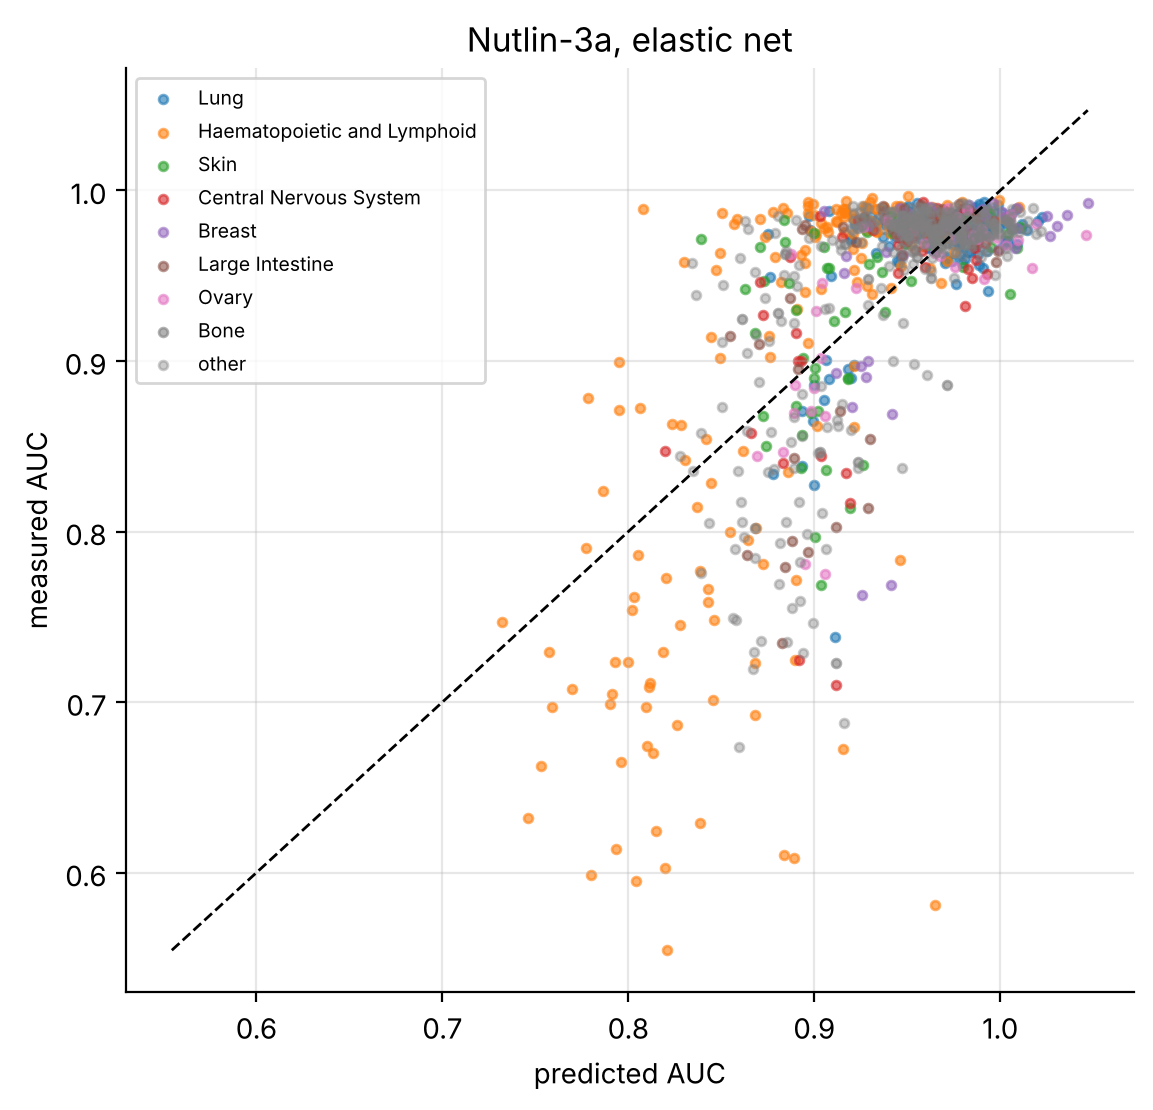

In [3]:
g = p[p.model == "Elastic net"]
t = S.M.tissue.reindex(g.line).values
fig, ax = plt.subplots(figsize=(6.5, 6))
for tt in pd.Series(t).value_counts().index[:8]:
    m = t == tt; ax.scatter(g.pred[m], g.actual[m], s=10, alpha=0.6, label=tt)
ax.scatter(g.pred[~pd.Series(t).isin(pd.Series(t).value_counts().index[:8]).values],
           g.actual[~pd.Series(t).isin(pd.Series(t).value_counts().index[:8]).values], s=10, alpha=0.4, c="grey", label="other")
lo, hi = g[["pred", "actual"]].min().min(), g[["pred", "actual"]].max().max()
ax.plot([lo, hi], [lo, hi], "k--", lw=1); ax.legend(fontsize=7)
ax.set(xlabel="predicted AUC", ylabel="measured AUC", title="Nutlin-3a, elastic net");

## Which genes, and how stable?

In [4]:
from drugresponse.evaluate import gene_frequency
for m in ["Elastic net", "Lasso"]:
    gf = gene_frequency(coefs, m, d)
    gf = gf[~gf.feature.str.startswith("tissue:")]
    print(f"{m}: {len(gf)} genes selected in at least one fold; {(gf.folds == 5).sum()} in all five")
    display(gf.head(12).round(4))

Elastic net: 318 genes selected in at least one fold; 34 in all five


,feature,folds,mean_coef,share
43,CDKN1A,5,-0.0168,1.0
209,PHLDA3,5,-0.0148,1.0
44,CDKN2A,5,0.0102,1.0
297,TRIM22,5,-0.0088,1.0
99,GLDC,5,-0.0071,1.0
1,ACTA2,5,-0.0059,1.0
39,CD82,5,0.0055,1.0
173,MIR4435-2HG,5,0.0055,1.0
227,PURPL,5,-0.0046,1.0
140,ITGAL,5,-0.0046,1.0


Lasso: 293 genes selected in at least one fold; 32 in all five


,feature,folds,mean_coef,share
38,CDKN1A,5,-0.0170,1.0
194,PHLDA3,5,-0.0149,1.0
39,CDKN2A,5,0.0103,1.0
274,TRIM22,5,-0.0088,1.0
90,GLDC,5,-0.0072,1.0
1,ACTA2,5,-0.0059,1.0
160,MIR4435-2HG,5,0.0057,1.0
36,CD82,5,0.0056,1.0
129,ITGAL,5,-0.0047,1.0
211,PURPL,5,-0.0046,1.0


Read the top genes against TP53 biology. Genes switched on by wild-type TP53 should have
**negative** coefficients, because their expression marks lines that respond. The most stable genes
include **CDKN1A** (p21), **PHLDA3**, **TRIM22**, **PURPL** and **PPP1R13L**, all known TP53 targets,
and all with negative coefficients. The model has rediscovered the drug's mechanism from expression
alone. **CDKN2A** (p16) enters with a *positive* coefficient (less sensitive). High p16 expression
is common in lines whose RB/p53 control is disrupted, which fits, but treat it as a hypothesis, not
a check. Learn/07 explains how to read signs and why a selected gene is not a significant one.

## How the penalty was chosen

In [5]:
cc = pd.DataFrame([c for c in coefs if c["model"] in ("Ridge", "Lasso", "Elastic net", "PCR")])
cc[["model", "fold", "alpha", "l1_ratio", "k", "n_nonzero"]].round(4)

,model,fold,alpha,l1_ratio,k,n_nonzero
0,Ridge,0,587.8016,NaN,NaN,2027
1,Lasso,0,0.0022,NaN,NaN,137
2,Elastic net,0,0.0095,0.2,NaN,180
3,PCR,0,NaN,NaN,200.0,2027
4,Ridge,1,587.8016,NaN,NaN,2027
5,Lasso,1,0.0025,NaN,NaN,114
6,Elastic net,1,0.0127,0.2,NaN,115
7,PCR,1,NaN,NaN,200.0,2027
8,Ridge,2,587.8016,NaN,NaN,2028
9,Lasso,2,0.0022,NaN,NaN,157
